##### Machine Learning LAB 1: MODEL SELECTION

Course 2026/27: *F. Chiariotti*

The notebook contains a simple learning task over which we will implement **MODEL SELECTION AND VALIDATION**.

Complete all the **required code sections**.

### IMPORTANT for the exam:

The functions you might be required to implement in the exam will have the same signature and parameters as the ones in the labs

## Polynomial Classification on Signal to Noise Ratios

In this notebook we are going to explore the use of polynomial classification with polynomial regression. We are going to use the Numpy **polyfit** function, which performs polynomial regression.

Our use case is a communication problem: we have a set of measurements of the Signal to Noise Ratio (SNR), i.e., the quality of the communication link, in various positions. The SNR depends on two components: firstly, the noise level (which is a random variable that does not depend on position) and the signal attenuation (usually modeled as a polynomial function of the distance).

Our transmitter is in (0,0), and coordinates are in meters. In urban scenarios, the attenuation usually follows a third-degree polynomial, but it might be a fourth- or fifth-degree polynomial in more complex cases. How do we choose between different degrees? We will try with a maximum of **6**

---

## Import all the necessary Python libraries

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import itertools
import random
from matplotlib import pyplot as plt

---

## Load the data

In this case, x and y are the two coordinates, and the SNR is the thing we are trying to predict

**DO NOT CHANGE THE PRE-WRITTEN CODE UNLESS OTHERWISE SPECIFIED**

In [2]:
df = pd.read_csv('data/snr_measurements.csv',sep=';')
#x = df['x'].to_numpy()
x = np.asarray(list(df['x']))
#y = df['y'].to_numpy()
y = np.asarray(list(df['y']))
#SNR = df['SNR'].to_numpy()
SNR = np.asarray(list(df['SNR']))

## Helper functions

These functions will help us evaluate the results

In [3]:
def compute_distance(x, y):
    # TODO: Compute the Euclidean distance from the origin
    distance=np.sqrt(x**2+y**2)
    return distance

def fit(distance, SNR, degree):
    return np.polyfit(distance, SNR, deg=degree)

def predict(distance, poly_coeffs):
    # Predict the SNR from a given model
    SNR=np.polyval(poly_coeffs,distance)
    return SNR

def evaluate(distance, SNR, poly_coeffs):
    # TODO: Compute the error of the polynomial fit on the chosen data
    diffs=SNR-predict(distance,poly_coeffs)
    mse=1/len(SNR)*sum((diffs)**2)
    return mse

def separate_test(distance, SNR, test_points):
    # TODO: Return a training set and a test set (the test_points parameter controls the number of test points).
    # The points should be selected randomly
    idx=[i for i in range (len(distance))]
    test_idx=random.sample(idx,test_points)
    train_idx=[j for j in idx if j not in test_idx]
    x_train=distance[train_idx]
    x_test=distance[test_idx]
    y_train=SNR[train_idx]
    y_test=SNR[test_idx]
    return x_train, y_train, x_test, y_test

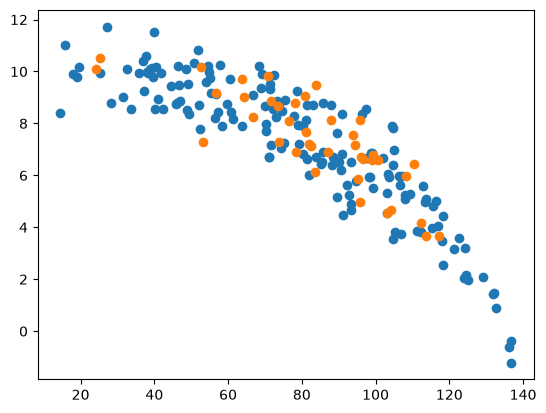

In [4]:
# TODO: separate the training and test sets and create a scatter plot of the SNR as a function of the distance
test_points=int(0.2*len(SNR))
distance=compute_distance(x,y)
x_train, y_train, x_test, y_test=separate_test(distance,SNR,test_points)
plt.scatter(x_train,y_train)
plt.scatter(x_test,y_test)

## A. K-fold cross-validation

In this case, x and y are the two coordinates, and the SNR is the thing we are trying to predict

In [5]:
# Function to perform the K-fold cross validation
def k_fold_cross_validation(x_train: np.ndarray, y_train: np.ndarray, k: int, max_degree: int) -> tuple[tuple, tuple]:
    # TODO: Perform K-fold cross-validation on the training set.
    # The two returned values are the best model and the list of results for all degrees up to max_degree.
    # The points should be selected randomly.
    # The inputs and labels are already in terms of distance and SNR
    
    ##To fold, shuffle first all indices and then take the ordered blocks of n/k indices
    n=len(x_train)
    best=[]
    results=[]
    idx=list(range(n))
    fold_points=n//k
    rest_points=n%k
    x_folds=[]
    y_folds=[]
    best_degree = None
    best_perf = float('inf')
    
    for j in range (k):
        if j==k-1:
            fold_size = fold_points+rest_points
        else:
            fold_size = fold_points
        rdm_idx=random.sample(idx, fold_size)
        idx=[j for j in idx if j not in rdm_idx]

        x_folds.append(x_train[rdm_idx])
        y_folds.append(y_train[rdm_idx])

    for deg in range(1,max_degree+1):
        degree_perf=0

        for test in range (k):
            x_val=x_folds[test]
            y_val=y_folds[test]
            x_tr=np.concatenate([x_folds[i] for i in range(k) if i != test])
            y_tr=np.concatenate([y_folds[i] for i in range(k) if i != test])

            poly_coeffs=fit(x_tr,y_tr,deg)
            degree_perf+=evaluate(x_val,y_val,poly_coeffs)
        avg_mse=degree_perf/k
        results.append(avg_mse)
        if avg_mse<best_perf:
            best_perf=avg_mse
            best_degree=deg
    best_coeffs=fit(x_train,y_train,best_degree)
    best=(best_degree,best_coeffs)
    return best, results

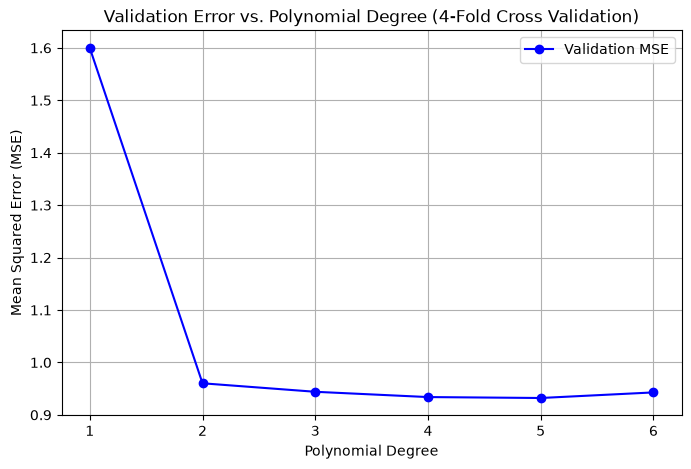

Miglior grado del polinomio scelto dalla Cross Validation: 5


In [6]:
# TODO: run the training with K-fold cross-validation with 40 test points and 4 folds Plot the validation score as a function of the degree
# 1. Separazione del dataset in Train e Test set (40 punti per il test)
x_train, y_train, x_test, y_test = separate_test(distance, SNR, test_points=40)

# 2. Esecuzione della K-fold cross-validation con K=4 e max_degree=6
k = 4
max_degree = 6
best_model, validation_scores = k_fold_cross_validation(x_train, y_train, k=k, max_degree=max_degree)

# 3. Grafico dello score di validazione (MSE) in funzione del grado del polinomio
degrees = list(range(1, max_degree + 1))

plt.figure(figsize=(8, 5))
plt.plot(degrees, validation_scores, marker='o', linestyle='-', color='b', label='Validation MSE')
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Validation Error vs. Polynomial Degree (4-Fold Cross Validation)')
plt.grid(True)
plt.xticks(degrees)
plt.legend()
plt.show()

# Stampa del miglior grado trovato
best_degree = best_model[0] if isinstance(best_model, tuple) else "N/A"
print(f"Miglior grado del polinomio scelto dalla Cross Validation: {best_degree}")

Best Degree: 5
Test MSE: 1.2625


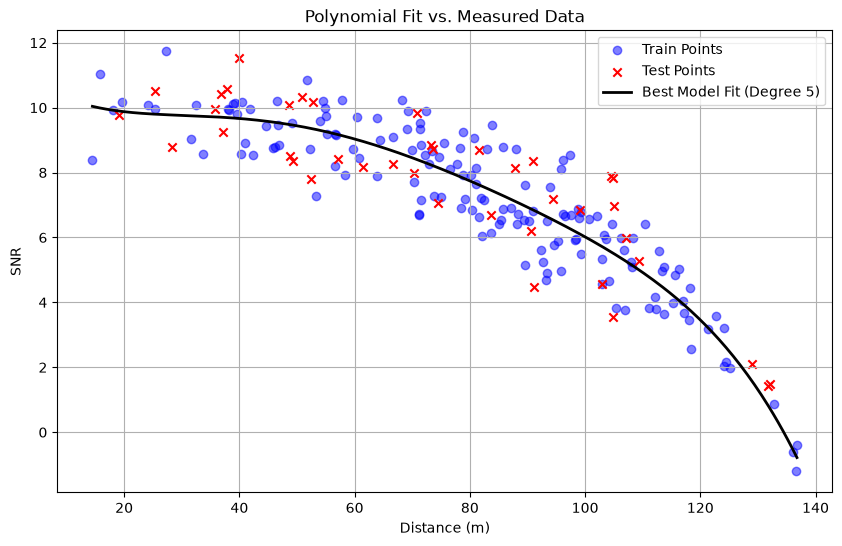

In [7]:
# TODO: get the test performance of the best model and plot the model output and test points. 
# Try running the program multiple times, changing the values of K and the number of test points: is the output always the same?
# 1. Extract best polynomial model coefficients
best_degree, best_coeffs = best_model

# 2. Evaluate performance on the held-out test set
test_mse = evaluate(x_test, y_test, best_coeffs)
print(f"Best Degree: {best_degree}")
print(f"Test MSE: {test_mse:.4f}")

# 3. Plot fitted curve vs actual points
x_range = np.linspace(min(distance), max(distance), 300)
y_pred_curve = predict(x_range, best_coeffs)

plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, color='blue', alpha=0.5, label='Train Points')
plt.scatter(x_test, y_test, color='red', marker='x', label='Test Points')
plt.plot(x_range, y_pred_curve, color='black', linewidth=2, label=f'Best Model Fit (Degree {best_degree})')

plt.xlabel('Distance (m)')
plt.ylabel('SNR')
plt.title('Polynomial Fit vs. Measured Data')
plt.legend()
plt.grid(True)
plt.show()

---

## B. Tikhonov regularization

Change the loss function to include a Tikhonov regularization term, as an alternative to cross-validation (try $\lambda=0.01$)

In [8]:
def evaluate_tikhonov(x_train: np.ndarray, y_train: np.ndarray, lambda_par: float, max_degree: int) -> tuple[tuple, tuple]:
    best_degree = None
    best_loss = float('inf')
    results = []
    
    for deg in range(1, max_degree + 1):
        # 1. Fit the polynomial model on the training data
        poly_coeffs = fit(x_train, y_train, deg)
        
        # 2. Compute mean squared error (MSE)
        mse = evaluate(x_train, y_train, poly_coeffs)
        
        # 3. Compute Tikhonov penalty (sum of squared coefficients)
        penalty = lambda_par * np.sum(poly_coeffs**2)
        
        # 4. Total regularized loss
        total_loss = mse + penalty
        results.append(total_loss)
        
        # Track the degree that minimizes the regularized loss
        if total_loss < best_loss:
            best_loss = total_loss
            best_degree = deg
            
    # Fit the best model on the training set
    best_coeffs = fit(x_train, y_train, best_degree)
    best = (best_degree, best_coeffs)
    
    return best, tuple(results)

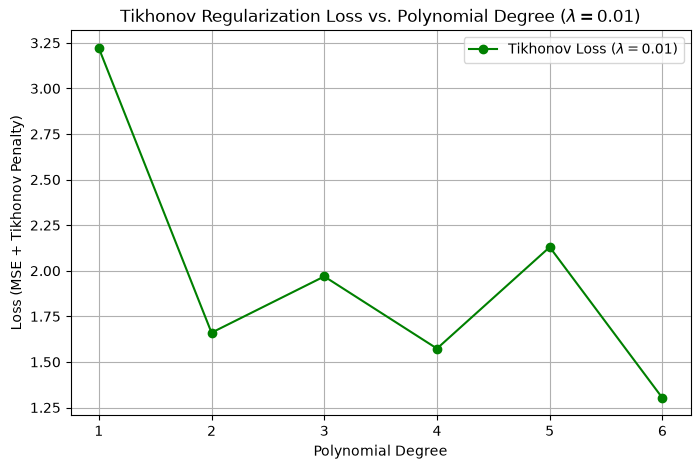

Miglior grado del polinomio scelto dalla regolarizzazione di Tikhonov: 6


In [9]:
# TODO: run the training with Tikhonov regularization and plot the loss as a function of the degree
# 1. Definizione dei parametri
lambda_par = 0.01
max_degree = 6

# 2. Esecuzione del training con regolarizzazione di Tikhonov
best_model_tik, tik_results = evaluate_tikhonov(x_train, y_train, lambda_par=lambda_par, max_degree=max_degree)

# 3. Grafico della Loss in funzione del grado del polinomio
degrees = list(range(1, max_degree + 1))

plt.figure(figsize=(8, 5))
plt.plot(degrees, tik_results, marker='o', linestyle='-', color='g', label=f'Tikhonov Loss ($\lambda={lambda_par}$)')
plt.xlabel('Polynomial Degree')
plt.ylabel('Loss (MSE + Tikhonov Penalty)')
plt.title(f'Tikhonov Regularization Loss vs. Polynomial Degree ($\lambda={lambda_par}$)')
plt.grid(True)
plt.xticks(degrees)
plt.legend()
plt.show()

# Stampa del risultato
best_degree_tik = best_model_tik[0]
print(f"Miglior grado del polinomio scelto dalla regolarizzazione di Tikhonov: {best_degree_tik}")

## C. Minimum description length regularization

Change the loss function to include a representation length regularization term, as an alternative to cross-validation. The minimum description length of a polynomial of degree N is O(2^N) - try $\lambda=0.02$

In [10]:
def evaluate_representation(x_train: np.ndarray, y_train: np.ndarray, lambda_par: float, max_degree: int) -> tuple[tuple, tuple]:
    best_degree = None
    best_loss = float('inf')
    results = []
    
    for deg in range(1, max_degree + 1):
        # 1. Fit del modello polinomiale
        poly_coeffs = fit(x_train, y_train, deg)
        
        # 2. Calcolo del Mean Squared Error (MSE)
        mse = evaluate(x_train, y_train, poly_coeffs)
        
        # 3. Penalità sulla lunghezza di rappresentazione: O(2^N)
        penalty = lambda_par * (2**deg)
        
        # 4. Calcolo della loss totale
        total_loss = mse + penalty
        results.append(total_loss)
        
        # Tracciamo il grado che minimizza la loss regolarizzata
        if total_loss < best_loss:
            best_loss = total_loss
            best_degree = deg
            
    # Fit del miglior modello sull'intero training set
    best_coeffs = fit(x_train, y_train, best_degree)
    best = (best_degree, best_coeffs)
    
    return best, tuple(results)

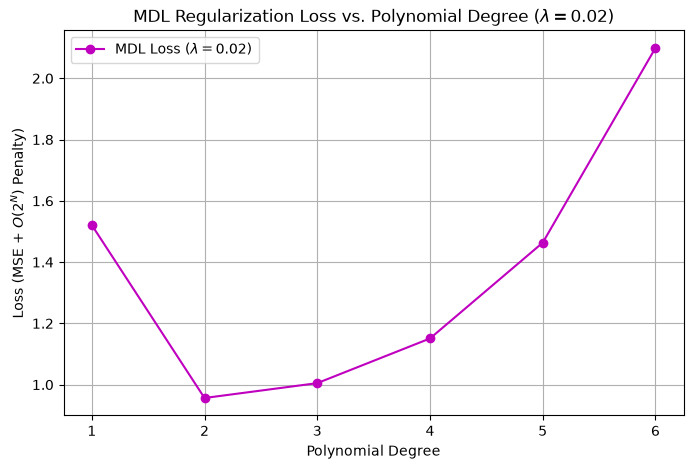

Miglior grado del polinomio scelto dalla regolarizzazione MDL: 2


In [11]:
# TODO: run the training with MDL regularization and plot the loss as a function of the degree
# 1. Definizione dei parametri
lambda_par = 0.02
max_degree = 6

# 2. Esecuzione dell'addestramento con la regolarizzazione MDL
best_model_mdl, mdl_results = evaluate_representation(x_train, y_train, lambda_par=lambda_par, max_degree=max_degree)

# 3. Grafico della Loss in funzione del grado del polinomio
degrees = list(range(1, max_degree + 1))

plt.figure(figsize=(8, 5))
plt.plot(degrees, mdl_results, marker='o', linestyle='-', color='m', label=f'MDL Loss ($\lambda={lambda_par}$)')
plt.xlabel('Polynomial Degree')
plt.ylabel('Loss (MSE + $O(2^N)$ Penalty)')
plt.title(f'MDL Regularization Loss vs. Polynomial Degree ($\lambda={lambda_par}$)')
plt.grid(True)
plt.xticks(degrees)
plt.legend()
plt.show()

# 4. Stampa del miglior grado selezionato
best_degree_mdl = best_model_mdl[0]
print(f"Miglior grado del polinomio scelto dalla regolarizzazione MDL: {best_degree_mdl}")

### TEST

Check the performance of the three solutions on the test set: which one does best?


--- TEST SET PERFORMANCE ---
K-Fold Cross-Validation : Degree 5 | Test MSE: 1.2625
Tikhonov Regularization  : Degree 6 | Test MSE: 1.2620
MDL Regularization       : Degree 2 | Test MSE: 1.2967


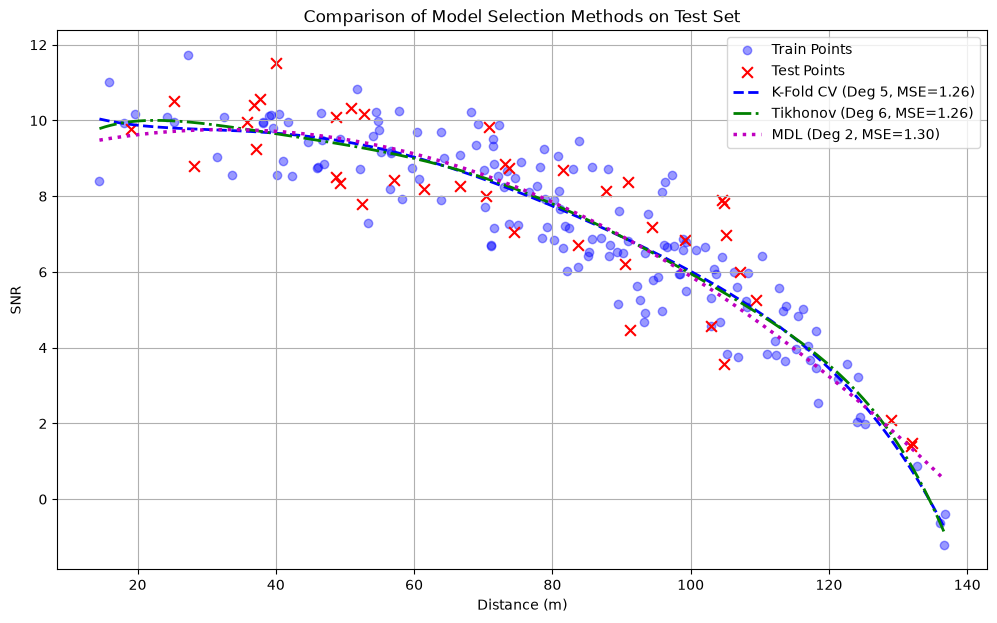

In [12]:
# TODO: plot the results
# 1. Extract best polynomial degrees and fit coefficients for each method
deg_cv, coeffs_cv = best_model           # From K-Fold Cross-Validation
deg_tik, coeffs_tik = best_model_tik     # From Tikhonov Regularization
deg_mdl, coeffs_mdl = best_model_mdl     # From MDL Regularization

# 2. Evaluate Mean Squared Error (MSE) on the held-out Test Set
mse_cv = evaluate(x_test, y_test, coeffs_cv)
mse_tik = evaluate(x_test, y_test, coeffs_tik)
mse_mdl = evaluate(x_test, y_test, coeffs_mdl)

print("--- TEST SET PERFORMANCE ---")
print(f"K-Fold Cross-Validation : Degree {deg_cv} | Test MSE: {mse_cv:.4f}")
print(f"Tikhonov Regularization  : Degree {deg_tik} | Test MSE: {mse_tik:.4f}")
print(f"MDL Regularization       : Degree {deg_mdl} | Test MSE: {mse_mdl:.4f}")

# 3. Plot fitted curves against training and test points
x_range = np.linspace(min(distance), max(distance), 300)

plt.figure(figsize=(12, 7))

# Scatter data points
plt.scatter(x_train, y_train, color='blue', alpha=0.4, label='Train Points')
plt.scatter(x_test, y_test, color='red', marker='x', s=60, label='Test Points')

# Plot model curves
plt.plot(x_range, predict(x_range, coeffs_cv), 'b--', linewidth=2, 
         label=f'K-Fold CV (Deg {deg_cv}, MSE={mse_cv:.2f})')
plt.plot(x_range, predict(x_range, coeffs_tik), 'g-.', linewidth=2, 
         label=f'Tikhonov (Deg {deg_tik}, MSE={mse_tik:.2f})')
plt.plot(x_range, predict(x_range, coeffs_mdl), 'm:', linewidth=2.5, 
         label=f'MDL (Deg {deg_mdl}, MSE={mse_mdl:.2f})')

plt.xlabel('Distance (m)')
plt.ylabel('SNR')
plt.title('Comparison of Model Selection Methods on Test Set')
plt.legend()
plt.grid(True)
plt.show()